# 8. 凍結2-stage Spatial LoRAの中身

2-stageは同seed M01のbackboneと元classifierを凍結し、metadata encoder・ΔW生成器だけを学習する。
ΔW=0ならM01そのものなので、adapterが**何を・どれだけ**変えたかを親との差として直接測れる。

1. 生成ΔWは元重みに対して大きいか。属性に依らない共通成分と、属性ごとに異なる成分のどちらが主か。
2. 予測は親M01からどれだけ動いたか。群ごとの一律のずれか、群内の並べ替えか。
3. raceや年齢だけを差し替えると予測はどれだけ動くか（反実仮想metadata）。
4. metadata encoderのcondition空間は、どの属性で張られているか。

4条件とも同seed M01（ResNet ERM）を親とする凍結2-stage Spatial LoRA＋Group DRO。違いは変調範囲とclass weight（CW）。
図では条件IDではなく下の名前で示す。

| ID | 変調範囲 | class weight | 図の表記 |
| --- | --- | --- | --- |
| M01 | — | — | parent ResNet ERM |
| M06 | stage3-4＋fc | global | Spatial LoRA stage3-4 / global CW |
| M13 | stage3-4＋fc | subgroup | Spatial LoRA stage3-4 / subgroup CW |
| M19 | stage1-4＋fc | global | Spatial LoRA stage1-4 / global CW |
| M20 | stage1-4＋fc | subgroup | Spatial LoRA stage1-4 / subgroup CW |

主対象はM06（stage3-4 / global CW）。残り3条件で再現を見る。
best validation AUROCのepochは0〜10と早い。生成器が未発達なだけかを見るため、lastを**補助診断**として並べる。
性能比較はbestに限り、lastで条件の優劣を述べない。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.archive.race_known_architecture_objective_comparison.comparison import (  # noqa: E402
    GROUP_LABELS,
    group_ids,
    read_predictions,
    select_runs,
)
from analysis.archive.race_known_architecture_objective_comparison.operating_point import (  # noqa: E402
    prediction_transitions,
)
from analysis.archive.race_known_architecture_objective_comparison.spatial_lora_inspection import (  # noqa: E402
    COUNTERFACTUAL_AGES,
    RACE_CODES,
    counterfactual_change,
    encoder_space,
    margin,
    prediction_change,
    probe_command,
    read_probe,
    weight_diagnostics,
)

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("race_known_architecture_objective_comparison")
TOPIC = "08_two_stage_spatial_lora_inspection"
SEEDS = [42, 43, 44]
CONDITIONS = {
    "M01": "resnet-chexpert-race-known",
    "M06": "spatial-lora-chexpert-from-resnet-age-race-group-dro-race-known",
    "M13": "spatial-lora-chexpert-from-resnet-age-race-group-dro-subgroup-race-known",
    "M19": "spatial-lora-chexpert-stage1-4-from-resnet-age-race-group-dro-race-known",
    "M20": "spatial-lora-chexpert-stage1-4-from-resnet-age-race-group-dro-subgroup-race-known",
}
# プロットに出す条件名。条件IDは表記に使わない。
# 4条件とも同seed M01を凍結した2-stage Spatial LoRA＋Group DROで、違いは変調範囲とclass weight（CW）だけ。
PARENT = "parent ResNet ERM"
TWO_STAGE = f"frozen 2-stage Spatial LoRA + Group DRO (from {PARENT})"
SPATIAL = {
    "M06": "Spatial LoRA stage3-4 / global CW",
    "M13": "Spatial LoRA stage3-4 / subgroup CW",
    "M19": "Spatial LoRA stage1-4 / global CW",
    "M20": "Spatial LoRA stage1-4 / subgroup CW",
}
KINDS = ["best", "last"]
# 重み・encoderの計算に使うdevice。学習中のGPUを避け、空いているものを明示する。
DEVICE = "cuda:0"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## 入力

成功run・best checkpoint・同seed M01親・splitを共通処理で照合する。lastもrun.jsonのSHA256と照合してから読む。
画像forwardが要る予測probe（ΔW=0経路・実際の属性・反実仮想属性）は`cache/`から読む。
不足時は提示コマンドをrepo rootで実行する（GPUを自動起動しない）。

In [2]:
provenance, frame, directories = select_runs(PACKAGE, CONDITIONS, SEEDS)
provenance.to_csv(RESULTS / "provenance.csv", index=False)
spatial_dirs = {key: path for key, path in directories.items() if key[0] in SPATIAL}
best_epochs = provenance.assign(best_epoch=provenance.checkpoint.str.extract(r"_(\d+)\.ckpt$")[0].astype(int))
display(best_epochs.pivot(index="condition", columns="seed", values="best_epoch"))
command = probe_command(PACKAGE, spatial_dirs, KINDS, device=DEVICE)
print(command or "全probe cacheが有効")

seed,42,43,44
condition,,,
M01,8,8,6
M06,3,7,9
M13,6,9,0
M19,0,4,10
M20,1,2,3


全probe cacheが有効


## 1. 生成ΔWの大きさと、属性による違い

一意な属性組（test 2,003組）ごとにΔW=(α/r)A(c)B(c)を実体化し、test件数で重み付けする。
元重みのFrobenius normで割った値で、

- `rms`：sqrt E||ΔW||²（全体の大きさ）
- `shared`：||μ||。全属性で共通の補正。属性に依らない通常のfine-tuningと同じ働き
- `varying`：sqrt E||ΔW−μ||²。属性によって変わる部分
- `between_group/race/age`：8群・race 4群・年齢2群の平均の散らばり（varyingのうち群で説明される部分）

rms² = shared² + varying²。varying²のうちbetween_group²以外は、8群の内側の違い（sex・view・ethnicity・年齢差など）。
相対normは凍結BNを挟むため出力の変化量そのものではない。出力側は次節で見る。

In [3]:
# 条件×seed×checkpointごとに、全adapter層（各stageのconv2とfc）の生成ΔWを分解する。
# weight_diagnosticsは画像を読まず、testの一意な属性組ごとにΔWを実体化してtest件数で重み付けし、
#   layers : 層ごとのrms/shared/varying/between_*（いずれも元重みのFrobenius normで割った相対値）
#   cosines: 層ごとの8群平均の偏差（μ_g−μ）どうしのcosine（後段のheatmapで使う）
# を返す。
weight_rows, cosine_rows = [], []
for (condition, seed), path in spatial_dirs.items():
    for kind in KINDS:
        layers, cosines = weight_diagnostics(path, kind, DEVICE)
        keys = {"condition": condition, "seed": seed, "checkpoint": kind}
        weight_rows.append(layers.assign(**keys))
        cosine_rows.append(cosines.assign(**keys))
weights = pd.concat(weight_rows, ignore_index=True)
# 層名"stage3.0.conv2"の先頭をstage名にする（fcは"fc"のまま）。
weights["stage"] = weights.layer.str.split(".").str[0]
group_cosine = pd.concat(cosine_rows, ignore_index=True)
weights.to_csv(RESULTS / "delta_weight_by_layer.csv", index=False)
group_cosine.to_csv(RESULTS / "delta_group_cosine.csv", index=False)

# stage単位の要約はCSVにだけ残す。seed内でstageに属する層を均等に平均してから、
# seed間の平均・標準偏差を取る。層ごとの値は次の図で見る。
columns = ["rms_rel", "shared_rel", "varying_rel", "between_group_rel", "between_race_rel", "between_age_rel"]
by_stage = weights.groupby(["condition", "checkpoint", "seed", "stage"], sort=False)[columns].mean()
stage_stats = by_stage.groupby(["condition", "checkpoint", "stage"], sort=False).agg(["mean", "std"])
stage_stats.to_csv(RESULTS / "delta_weight_stage_mean_std.csv")

/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


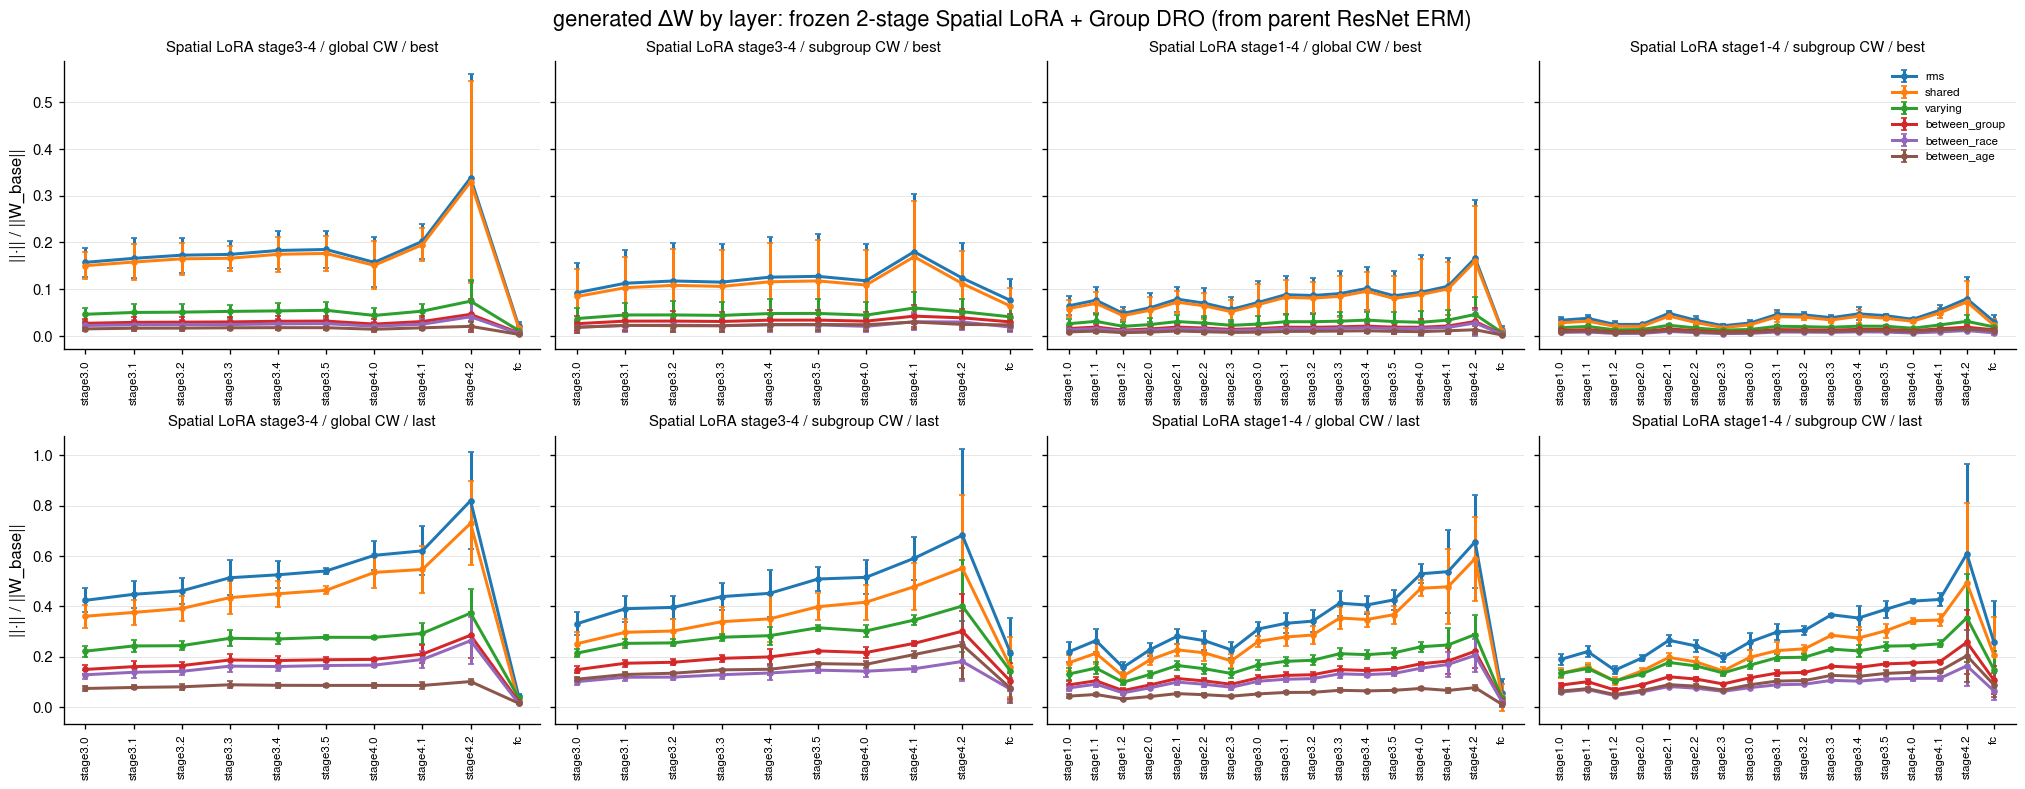

In [4]:
# 層ごとの相対normを、forward順に折れ線で描く。点はseed平均、棒はseed間の標準偏差。
# 行がcheckpoint（上best・下last）、列が条件。rms²=shared²+varying²なので、
# sharedがrmsにほぼ重なっていれば、その層のΔWは属性に依らない共通の補正が主。
fig, axes = plt.subplots(
    2, len(SPATIAL), figsize=(4.2 * len(SPATIAL), 6.5), sharey="row", layout="constrained", squeeze=False
)
colors = dict(zip(columns, plt.get_cmap("tab10").colors, strict=False))
for row, kind in enumerate(KINDS):
    for col, condition in enumerate(SPATIAL):
        ax = axes[row, col]
        selected = weights[(weights.condition == condition) & (weights.checkpoint == kind)]
        # weight_diagnosticsが返した層の並び（forward順）をx軸の順にする。
        order = list(dict.fromkeys(selected.layer))
        for column in columns:
            # 層ごとに3seedの平均と標準偏差を取る。
            stats = selected.groupby("layer")[column].agg(["mean", "std"]).reindex(order)
            ax.errorbar(
                range(len(order)),
                stats["mean"],
                yerr=stats["std"],
                marker=".",
                capsize=2,
                color=colors[column],
                label=column.removesuffix("_rel"),
            )
        ax.set_xticks(range(len(order)), [name.removesuffix(".conv2") for name in order], rotation=90, fontsize=7)
        ax.set_title(f"{SPATIAL[condition]} / {kind}", fontsize=9)
    axes[row, 0].set_ylabel("||·|| / ||W_base||")
axes[0, -1].legend(fontsize=7)
fig.suptitle(f"generated ΔW by layer: {TWO_STAGE}")
fig.savefig(FIGURES / "delta_weight_by_layer.png", dpi=160)
plt.show()

大きさの内訳を二乗（エネルギー）の割合で示す。sharedが大半なら、adapterは主に属性に依らない補正を学んでいる。
層は各stageのconv2を均等に平均し、fcは別に示す。

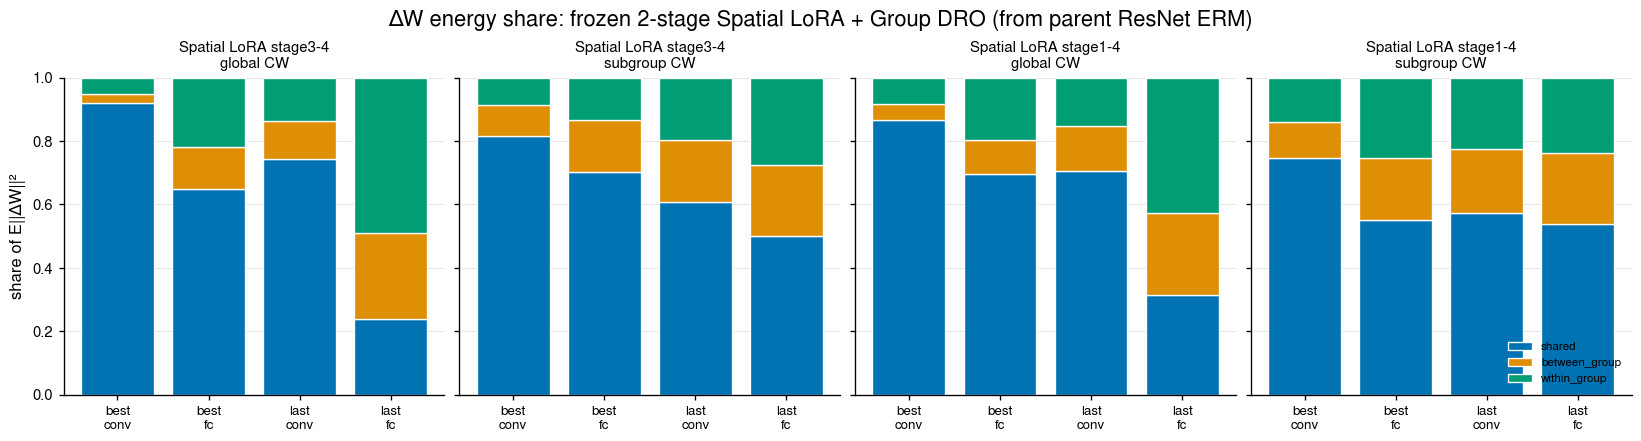

In [5]:
# 各層のΔWのエネルギー（rms²）を3つに分ける。
#   shared       = shared²/rms²         ：全属性で共通の補正
#   between_group= between_group²/rms²  ：8群（年齢2×race4）の平均の違い
#   within_group = 残り                 ：8群の内側の違い（sex・view・年齢差など）
# 割合にしてから層を均等に平均するので、normの大きい層に引っ張られない。
energy = weights.assign(
    shared=weights.shared_rel**2 / weights.rms_rel**2,
    between_group=weights.between_group_rel**2 / weights.rms_rel**2,
)
energy["within_group"] = 1 - energy.shared - energy.between_group
# convとfcは大きさも役割も違うので分けて集計する。
energy["part"] = np.where(energy.layer == "fc", "fc", "conv")
# seed内で層を平均し、seed間の平均・標準偏差を取る。数値はCSVで確認する。
shares = energy.groupby(["condition", "checkpoint", "part", "seed"], sort=False)[
    ["shared", "between_group", "within_group"]
].mean()
share_stats = shares.groupby(["condition", "checkpoint", "part"], sort=False).agg(["mean", "std"])
share_stats.to_csv(RESULTS / "delta_energy_share_mean_std.csv")

# 条件ごとに、checkpoint×(conv, fc)の4本を積み上げ棒で並べる（3seed平均）。
parts = ["shared", "between_group", "within_group"]
bars = [(kind, part) for kind in KINDS for part in ("conv", "fc")]
fig, axes = plt.subplots(1, len(SPATIAL), figsize=(3.4 * len(SPATIAL), 3.6), sharey=True, layout="constrained")
for ax, condition in zip(axes, SPATIAL, strict=True):
    means = share_stats.loc[condition].xs("mean", axis=1, level=1).reindex(bars)
    bottom = np.zeros(len(bars))
    for part in parts:
        ax.bar(range(len(bars)), means[part], bottom=bottom, label=part)
        bottom += means[part].to_numpy()
    ax.set_xticks(range(len(bars)), [f"{kind}\n{part}" for kind, part in bars], fontsize=8)
    ax.set_title(SPATIAL[condition].replace(" / ", "\n"), fontsize=9)
axes[0].set(ylabel="share of E||ΔW||²", ylim=(0, 1))
axes[-1].legend(fontsize=7, loc="lower right")
fig.suptitle(f"ΔW energy share: {TWO_STAGE}")
fig.savefig(FIGURES / "delta_energy_share.png", dpi=160)
plt.show()

8群の平均ΔWの偏差（μ_g−μ）どうしのcosine。1に近い群は同じ向きへ、−1に近い群は逆向きへ補正されている。
M06の最終conv（stage4.2）とfcを、seed別にbest/lastで並べる。seed間でパターンが似ていれば、群ごとの補正の向きは再現している。

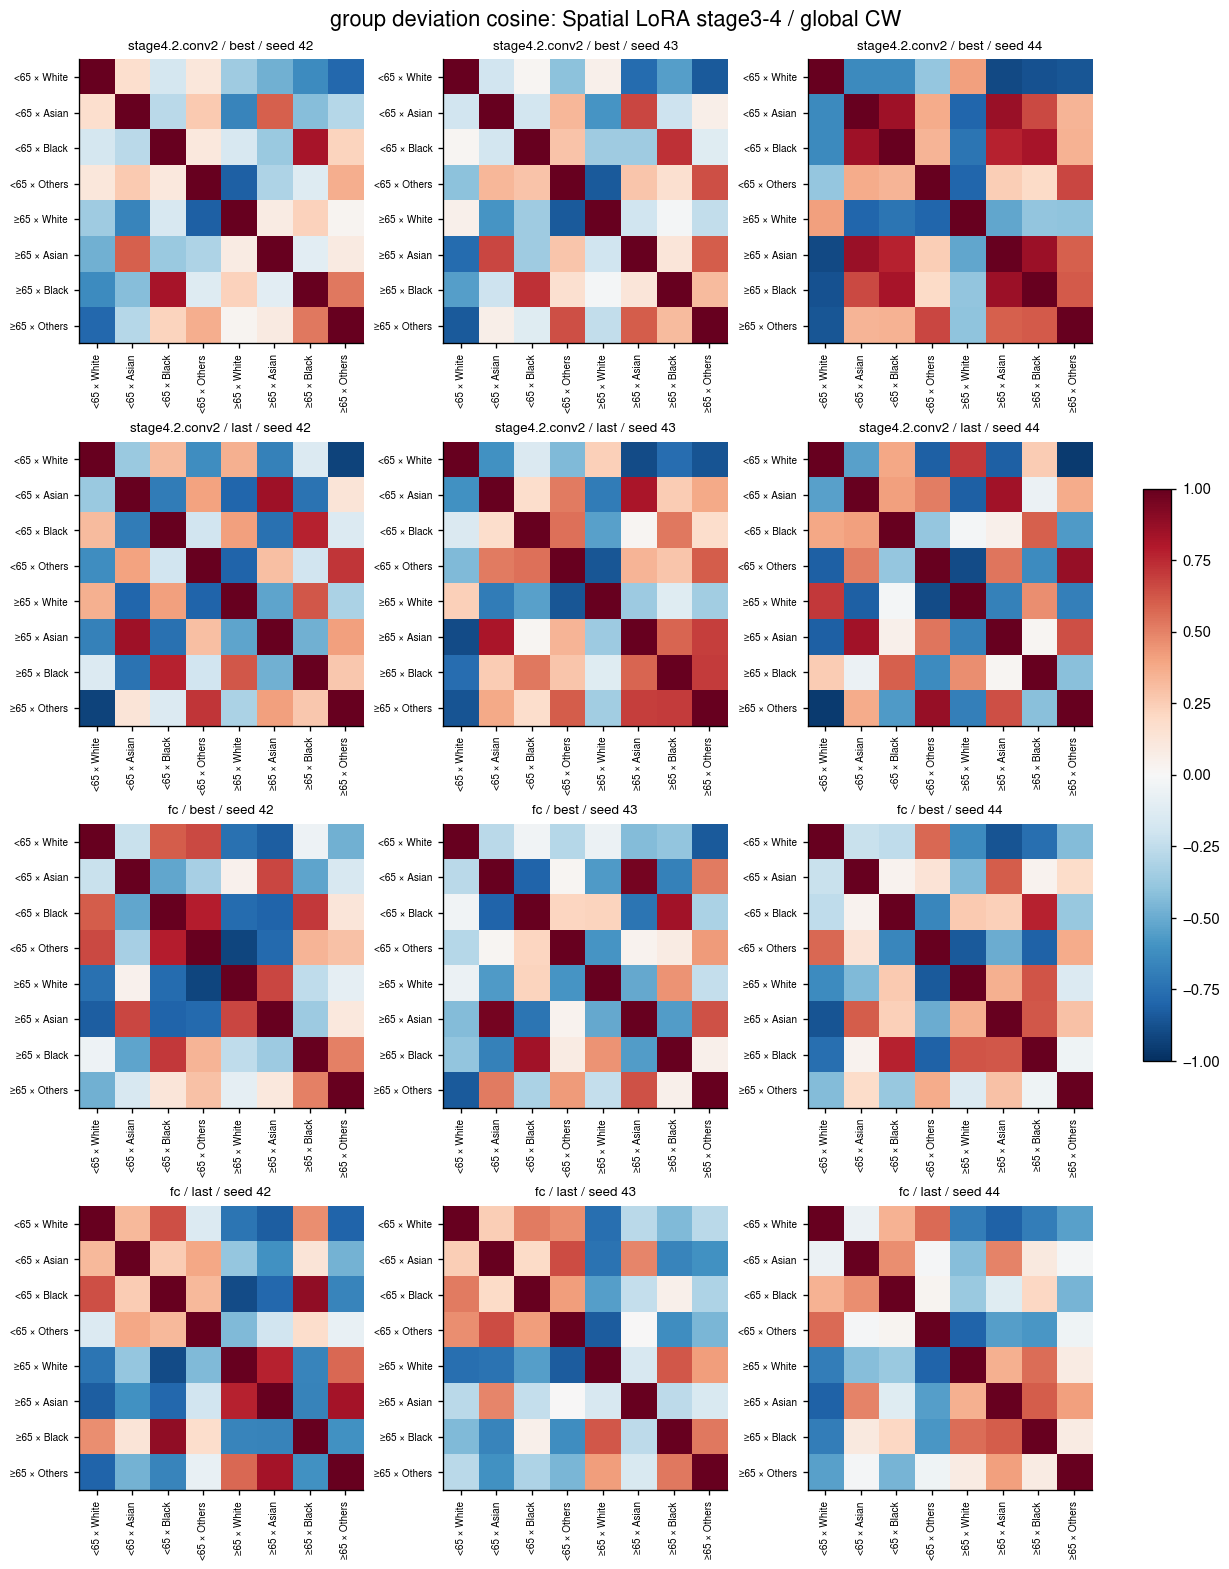

In [6]:
# M06（stage3-4 / global CW）について、8群平均ΔWの偏差（μ_g−μ）どうしのcosineを8×8のheatmapで描く。
# 行が(層, checkpoint)：stage4.2.conv2のbest/last、fcのbest/last。列がseed。
# 共通補正μを引いた残りの向きを比べるので、赤は「同じ向きにずらされる群」、青は「逆向き」。
fig, axes = plt.subplots(4, len(SEEDS), figsize=(3.4 * len(SEEDS), 13), layout="constrained")
panels = [(kind, layer) for layer in ("stage4.2.conv2", "fc") for kind in KINDS]
for row, (kind, layer) in enumerate(panels):
    for col, seed in enumerate(SEEDS):
        selected = group_cosine.query(
            "condition == 'M06' and seed == @seed and checkpoint == @kind and layer == @layer"
        )
        # 縦持ちの(group_a, group_b, cosine)を8×8行列に戻す。
        matrix = selected.pivot(index="group_a", columns="group_b", values="cosine")
        image = axes[row, col].imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
        axes[row, col].set_xticks(range(8), GROUP_LABELS, rotation=90, fontsize=6)
        axes[row, col].set_yticks(range(8), GROUP_LABELS, fontsize=6)
        axes[row, col].set_title(f"{layer} / {kind} / seed {seed}", fontsize=8)
        axes[row, col].grid(False)
fig.colorbar(image, ax=axes, shrink=0.4)
fig.suptitle(f"group deviation cosine: {SPATIAL['M06']}")
fig.savefig(FIGURES / "delta_group_cosine_m06.png", dpi=160)
plt.show()

## 2. 親M01からの予測変化

まずprobeのΔW=0経路が同seed M01の予測cacheと一致すること（凍結親の検算）、M06の実際の属性での出力が既存cacheと一致することを確かめる。

指標はlogit margin（陽性−陰性、softmax確率=sigmoid(margin)）。符号が固定argmaxの判定、絶対値が確信の強さ。
以下の要約列は`prediction_change_mean_std.csv`に書き出す（表示はしない）。

- `mean_abs_delta_margin`：|actual−base|の平均。`base_margin_sd`（親のmarginの広がり）と比べて大きさを読む
- `flip_rate`：固定argmaxの判定が親から変わった割合
- `group_offset_share`：Δmarginの分散のうち8群平均で説明される割合。1に近いほど「群ごとの一律のずれ（閾値移動）」。全群共通のずれは分散に入らない
- `auroc_offset_only`：親に群平均Δだけを足した予測のAUROC。actualとの差が群内の補正の寄与
- `feature_shift`：分類直前特徴の||f−f_base||/||f_base||

In [7]:
# 3seedのM01・M06予測cacheを読む（検算の相手）。
images = frame["image"].to_numpy(dtype=str)
target = frame["target"].to_numpy()
groups = group_ids(frame)
reference = read_predictions(
    PACKAGE, {key: path for key, path in directories.items() if key[0] in ("M01", "M06")}, frame
)
# probe cache：各(条件, seed, checkpoint)について、test全画像の
#   logits_base   : ΔW=0（= 凍結した親M01）の出力
#   logits_actual : 実際の属性を入れた出力
#   logits_counterfactual : raceや年齢を差し替えた出力（3節）
#   feature_shift / feature_cosine : 分類直前特徴の親からの変化
probes = {(*key, kind): read_probe(PACKAGE, path, kind, images) for key, path in spatial_dirs.items() for kind in KINDS}

# 検算1：ΔW=0経路が同seedのM01 cacheと一致するか。
# 検算2：M06 bestの実際の出力が学習側で作った予測cacheと一致するか（cacheがあるのはM06 bestだけ）。
checks = []
for (condition, seed, kind), probe in probes.items():
    parent = reference["M01", seed]["logits"]
    own = reference.get((condition, seed))
    checks.append(
        {
            "condition": condition,
            "seed": seed,
            "checkpoint": kind,
            "max_abs_base_vs_M01": np.abs(probe["logits_base"] - parent).max(),
            "max_abs_actual_vs_cache": np.abs(probe["logits_actual"] - own["logits"]).max()
            if own is not None and kind == "best"
            else np.nan,
        }
    )
checks = pd.DataFrame(checks)
checks.to_csv(RESULTS / "probe_checks.csv", index=False)
if (checks.max_abs_base_vs_M01 > 1e-4).any() or (checks.max_abs_actual_vs_cache > 1e-4).any():
    raise ValueError("ΔW=0経路が親M01と、または実際の出力が予測cacheと一致しない")
print(
    f"検算OK：ΔW=0 vs M01 最大差 {checks.max_abs_base_vs_M01.max():.1e}、"
    f"M06 actual vs cache 最大差 {checks.max_abs_actual_vs_cache.max():.1e}"
)

検算OK：ΔW=0 vs M01 最大差 0.0e+00、M06 actual vs cache 最大差 0.0e+00


In [8]:
# 各probeについて親からの変化を要約する（定義は上のmarkdown、実装はprediction_change）。
#   row      : test全体の要約1行
#   by_group : 8群ごとの平均Δmargin・群内標準偏差・群内Spearman・flip率・群内AUROC
change_rows, change_groups = [], []
for (condition, seed, kind), probe in probes.items():
    row, by_group = prediction_change(probe, target, groups)
    keys = {"condition": condition, "seed": seed, "checkpoint": kind}
    change_rows.append({**keys, **row})
    change_groups.append(by_group.assign(**keys, group=lambda data: [GROUP_LABELS[i] for i in data.group_id]))
changes = pd.DataFrame(change_rows)
change_groups = pd.concat(change_groups, ignore_index=True)
changes.to_csv(RESULTS / "prediction_change_by_seed.csv", index=False)
change_groups.to_csv(RESULTS / "prediction_change_by_group.csv", index=False)
# seed間の平均・標準偏差はCSVにだけ残す。
change_stats = changes.drop(columns="seed").groupby(["condition", "checkpoint"], sort=False).agg(["mean", "std"])
change_stats.to_csv(RESULTS / "prediction_change_mean_std.csv")

群別のΔmargin（点：群平均、棒：群内標準偏差、3seed平均）と、群内での親との順位相関。
群平均が群ごとに大きく違えば群別の閾値移動、群内標準偏差が大きく順位相関が下がれば群内の並べ替え。

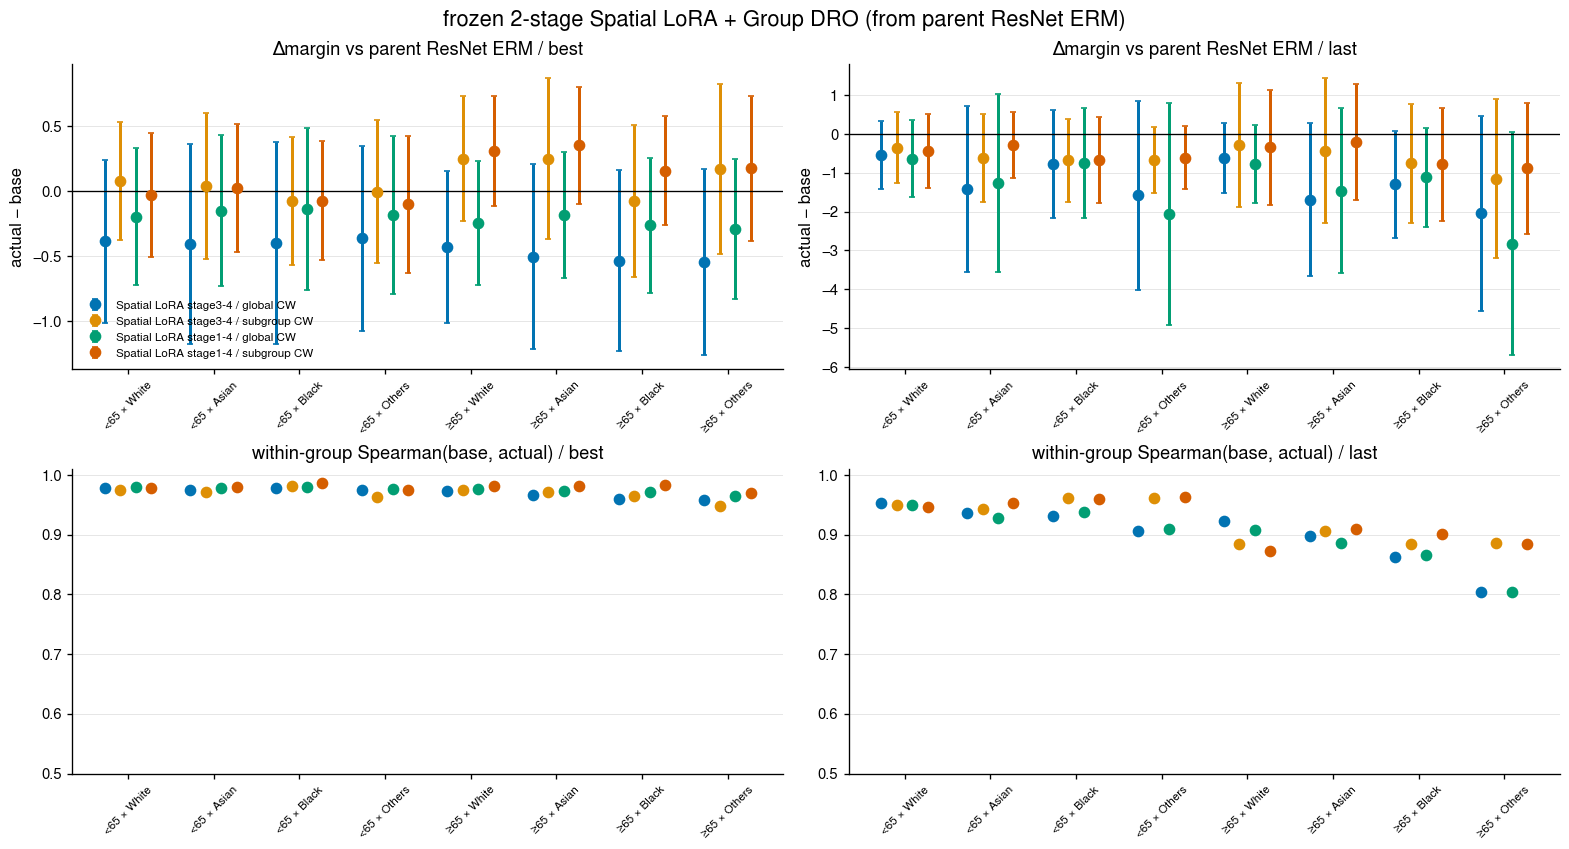

In [9]:
# 群別の指標を3seedで平均する（seed内で群ごとに求めた値の平均）。
group_stats = change_groups.groupby(["condition", "checkpoint", "group_id"], sort=False)[
    ["mean_delta_margin", "sd_delta_margin", "spearman_base_actual", "flip_rate", "auroc_base", "auroc_actual"]
].mean()
group_stats.to_csv(RESULTS / "prediction_change_group_mean.csv")
# 上段：群平均Δmargin（点）と群内標準偏差（棒）。棒はseed間のばらつきではない。
# 下段：群内でのbaseとactualの順位相関。1なら群内の並びは親のまま。
# 列はcheckpoint（左best・右last）。条件は各群の位置で横にずらして並べる。
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout="constrained")
for col, kind in enumerate(KINDS):
    for offset, condition in enumerate(SPATIAL):
        stats = group_stats.loc[(condition, kind)]
        x = np.arange(8) + (offset - 1.5) * 0.18
        axes[0, col].errorbar(
            x,
            stats.mean_delta_margin,
            yerr=stats.sd_delta_margin,
            fmt="o",
            capsize=2,
            label=SPATIAL[condition],
        )
        axes[1, col].plot(x, stats.spearman_base_actual, "o", label=SPATIAL[condition])
    axes[0, col].axhline(0, color="black", linewidth=0.8)
    axes[0, col].set(title=f"Δmargin vs {PARENT} / {kind}", ylabel="actual − base")
    axes[1, col].set(title=f"within-group Spearman(base, actual) / {kind}", ylim=(0.5, 1.01))
    for row in range(2):
        axes[row, col].set_xticks(range(8), GROUP_LABELS, rotation=45, fontsize=7)
axes[0, 0].legend(fontsize=7)
fig.suptitle(TWO_STAGE)
fig.savefig(FIGURES / "prediction_change_by_group.png", dpi=160)
plt.show()

M06 seed 42の親margin対実際のmargin。対角線上なら変化なし、平行移動なら一律の補正、ばらつきが群内の補正。

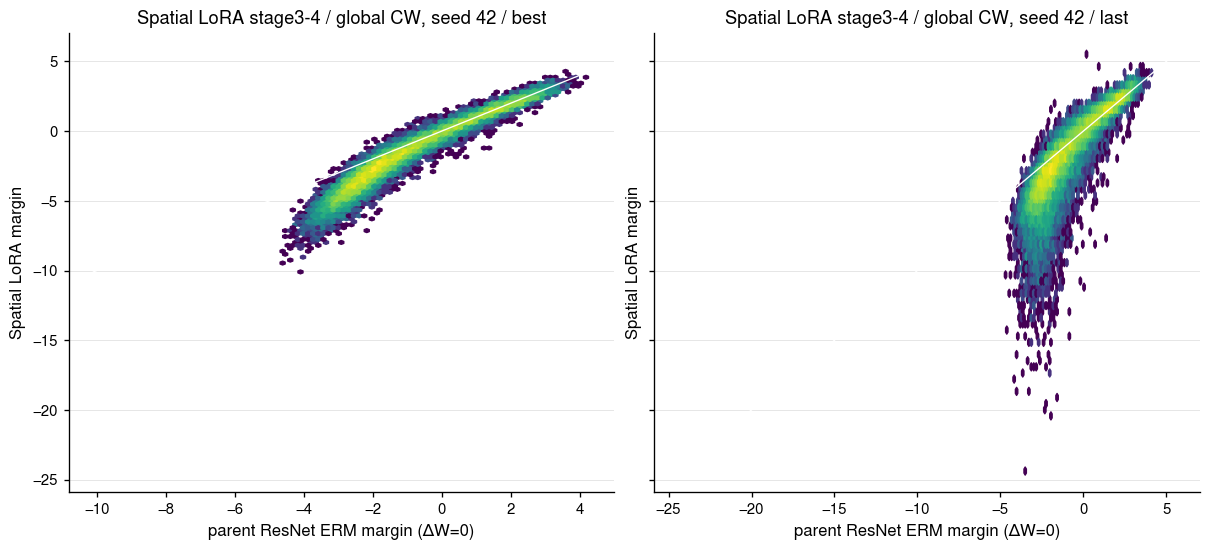

In [10]:
# M06（stage3-4 / global CW）seed 42の画像ごとの(親margin, 実際のmargin)を2次元ヒストグラム（対数色）で描く。
# 白線が対角線（変化なし）。左右でbest/lastを比べる。
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained", sharey=True)
for ax, kind in zip(axes, KINDS, strict=True):
    probe = probes["M06", 42, kind]
    base, actual = margin(probe["logits_base"]), margin(probe["logits_actual"])
    ax.hexbin(base, actual, gridsize=60, bins="log", cmap="viridis")
    limits = [min(base.min(), actual.min()), max(base.max(), actual.max())]
    ax.plot(limits, limits, color="white", linewidth=0.8)
    ax.set(title=f"{SPATIAL['M06']}, seed 42 / {kind}", xlabel=f"{PARENT} margin (ΔW=0)", ylabel="Spatial LoRA margin")
fig.savefig(FIGURES / "margin_scatter_m06_s42.png", dpi=160)
plt.show()

### 判定が変わった画像は、良い方向に変わったか

marginの変化のうち、固定argmax（margin=0）の判定をまたいだ画像だけを取り出し、正解ラベルと照らして4通りに分ける。

- 陽性：FN→TP（改善）、TP→FN（悪化）
- 陰性：FP→TN（改善）、TN→FP（悪化）

集計は07と同じ`prediction_transitions`（8群に入る画像のみ）。testは陽性が約1割なので、test画像数に対する件数では陰性の変化が支配的になり、
良し悪しを読めない。そこで陽性・陰性それぞれの件数に対する割合で示す。正味（改善−悪化）はそのままΔTPR・ΔTNRになり、
BACC＝(TPR+TNR)/2の変化はその平均になる。

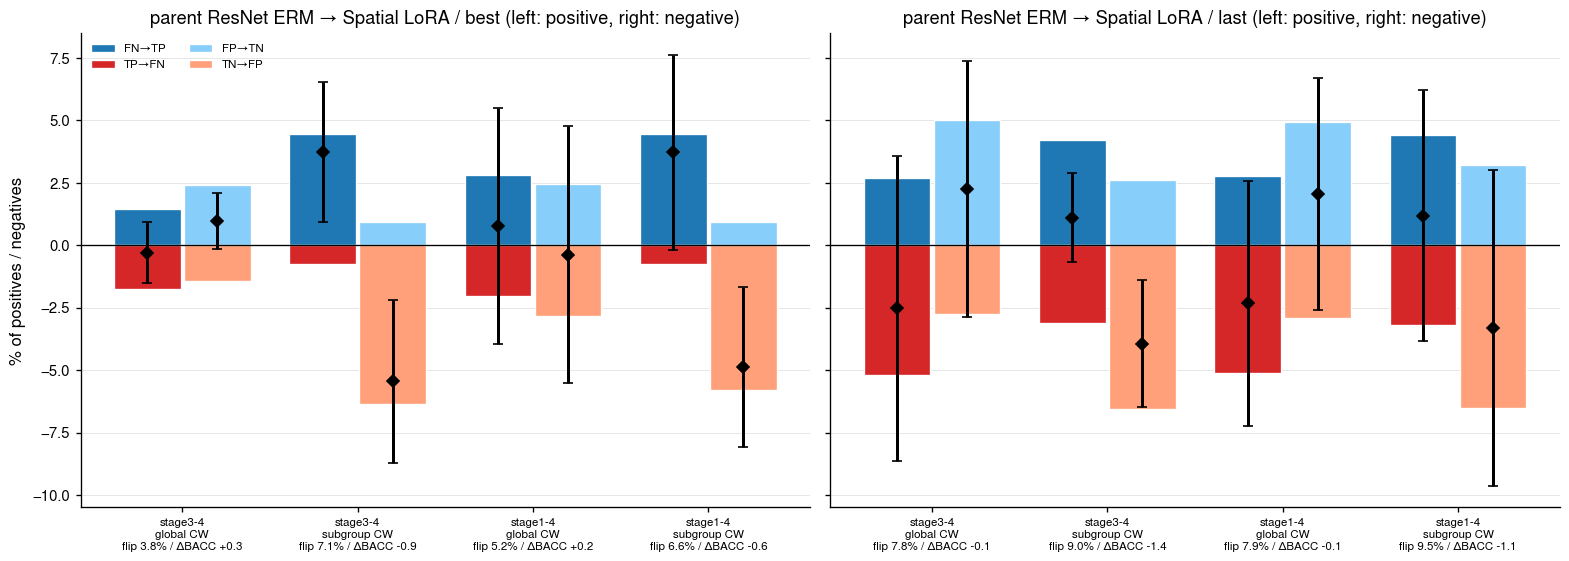

In [11]:
# prediction_transitionsは(条件, seed)→{"target", "predictions"}のcacheを受け取る。
# 親M01の判定はΔW=0経路のargmax、比較側は実際の属性でのargmax。
# ΔW=0経路は全probeで同seedのM01と一致する（上の検算）ので、M01は上書きしても同じ値になる。
transition_caches = {}
for (condition, seed, kind), probe in probes.items():
    transition_caches["M01", seed] = {"target": target, "predictions": probe["logits_base"].argmax(1)}
    transition_caches[f"{condition} {kind}", seed] = {
        "target": target,
        "predictions": probe["logits_actual"].argmax(1),
    }
transition_pairs = [("M01", f"{condition} {kind}") for kind in KINDS for condition in SPATIAL]
transitions = prediction_transitions(transition_caches, frame, transition_pairs, SEEDS)
transitions.to_csv(RESULTS / "flip_transitions_by_seed.csv", index=False)

# 8群を合計してtest全体の件数にし、seedごとに率へ直す。
#   陽性側：FN→TP・TP→FNを陽性数で割る。正味がΔTPR
#   陰性側：FP→TN・TN→FPを陰性数で割る。正味がΔTNR
#   flip  ：4通りの合計をtest画像数で割る（判定が変わった画像の割合）
moves = ["FN_to_TP", "TP_to_FN", "FP_to_TN", "TN_to_FP"]
totals = transitions.groupby(["pair", "seed"], sort=False)[[*moves, "n_positive", "n_negative"]].sum()
rates = pd.DataFrame(
    {
        "FN_to_TP": totals.FN_to_TP / totals.n_positive,
        "TP_to_FN": totals.TP_to_FN / totals.n_positive,
        "FP_to_TN": totals.FP_to_TN / totals.n_negative,
        "TN_to_FP": totals.TN_to_FP / totals.n_negative,
        "flip": totals[moves].sum(axis=1) / (totals.n_positive + totals.n_negative),
    }
)
rates["delta_tpr"] = rates.FN_to_TP - rates.TP_to_FN
rates["delta_tnr"] = rates.FP_to_TN - rates.TN_to_FP
rates["delta_bacc"] = (rates.delta_tpr + rates.delta_tnr) / 2
rates = rates * 100  # %表示
rate_stats = rates.groupby("pair", sort=False).agg(["mean", "std"])
rate_stats.to_csv(RESULTS / "flip_rates_mean_std.csv")

# 条件ごとに陽性・陰性の2本を並べ、改善を上向き・悪化を下向きに描く（3seed平均）。
# ◆が正味（ΔTPR・ΔTNR）とseed間の標準偏差。目盛りの下段は判定が変わった画像の割合とΔBACC。
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, layout="constrained")
for ax, kind in zip(axes, KINDS, strict=True):
    pairs = [f"M01 → {condition} {kind}" for condition in SPATIAL]
    means = rate_stats.xs("mean", axis=1, level=1).loc[pairs]
    stds = rate_stats.xs("std", axis=1, level=1).loc[pairs]
    x = np.arange(len(pairs))
    for shift, improved, worsened, net, colors, label in [
        (-0.2, "FN_to_TP", "TP_to_FN", "delta_tpr", ("tab:blue", "tab:red"), "positive"),
        (0.2, "FP_to_TN", "TN_to_FP", "delta_tnr", ("lightskyblue", "lightsalmon"), "negative"),
    ]:
        ax.bar(x + shift, means[improved], width=0.38, color=colors[0], label=improved.replace("_to_", "→"))
        ax.bar(x + shift, -means[worsened], width=0.38, color=colors[1], label=worsened.replace("_to_", "→"))
        ax.errorbar(x + shift, means[net], yerr=stds[net], fmt="D", color="black", capsize=3, markersize=5)
    ax.axhline(0, color="black", linewidth=0.8)
    ticks = []
    for condition, pair in zip(SPATIAL, pairs, strict=True):
        name = SPATIAL[condition].removeprefix("Spatial LoRA ").replace(" / ", "\n")
        ticks.append(f"{name}\nflip {means.flip[pair]:.1f}% / ΔBACC {means.delta_bacc[pair]:+.1f}")
    ax.set_xticks(x, ticks, fontsize=7)
    ax.set_title(f"{PARENT} → Spatial LoRA / {kind} (left: positive, right: negative)")
axes[0].set_ylabel("% of positives / negatives")
axes[0].legend(fontsize=7, loc="upper left", ncols=2)
fig.savefig(FIGURES / "flip_direction_overall.png", dpi=160)
plt.show()

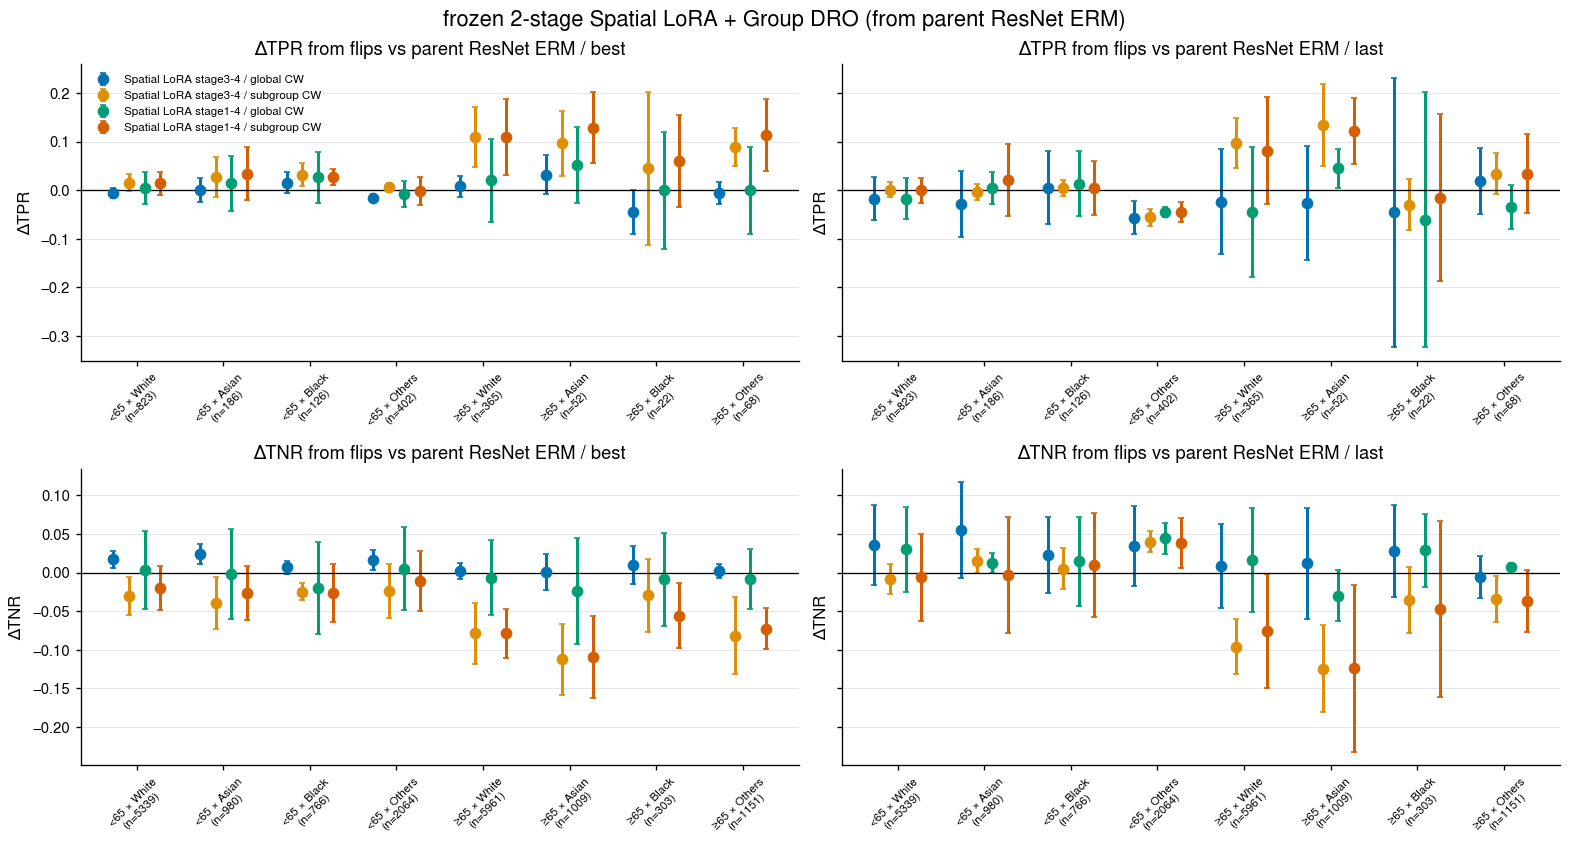

In [12]:
# 群ごとの正味の判定変更を率にする：ΔTPR＝(FN→TP − TP→FN)/陽性数、ΔTNR＝(FP→TN − TN→FP)/陰性数。
# seedごとに率にしてから3seedの平均・標準偏差を取る。
transitions["delta_tpr"] = transitions.net_positive / transitions.n_positive
transitions["delta_tnr"] = transitions.net_negative / transitions.n_negative
group_flip = transitions.groupby(["pair", "group_id"], sort=False)[["delta_tpr", "delta_tnr"]].agg(["mean", "std"])
group_flip.to_csv(RESULTS / "flip_group_rates_mean_std.csv")

# 群の件数は全seedで同じtestなのでseed 42の値を目盛りに添える（少数群の揺れを読むため）。
counts = transitions[transitions.seed == SEEDS[0]].drop_duplicates("group_id").set_index("group_id").sort_index()
# 行：ΔTPR・ΔTNR、列：best・last。点が3seed平均、棒がseed間の標準偏差。0より上が親より改善。
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey="row", layout="constrained")
for col, kind in enumerate(KINDS):
    for offset, condition in enumerate(SPATIAL):
        stats = group_flip.loc[f"M01 → {condition} {kind}"]
        x = np.arange(8) + (offset - 1.5) * 0.18
        for row, metric in enumerate(["delta_tpr", "delta_tnr"]):
            axes[row, col].errorbar(
                x,
                stats[metric]["mean"],
                yerr=stats[metric]["std"],
                fmt="o",
                capsize=2,
                label=SPATIAL[condition],
            )
    for row, (metric, column) in enumerate([("ΔTPR", "n_positive"), ("ΔTNR", "n_negative")]):
        ax = axes[row, col]
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set(title=f"{metric} from flips vs {PARENT} / {kind}", ylabel=metric)
        ticks = [f"{label}\n(n={n})" for label, n in zip(GROUP_LABELS, counts[column], strict=True)]
        ax.set_xticks(range(8), ticks, rotation=45, fontsize=7)
axes[0, 0].legend(fontsize=7)
fig.suptitle(TWO_STAGE)
fig.savefig(FIGURES / "flip_direction_by_group.png", dpi=160)
plt.show()

**観察（best中心、lastは補助）**

- 判定が変わる画像はbestで3.8〜7.1%。global CW（M06・M19）は少なく、subgroup CW（M13・M20）は約2倍。
- stage3-4 / global CW（M06）：陰性で改善（FP→TN）が悪化を上回り、陽性はほぼ相殺。ΔTNR +1.0、ΔTPR −0.3、ΔBACC +0.3（seed間で安定）。
  全体を陰性方向へ一律にずらした（2節の図）結果、主に偽陽性が減った。群別でも<65の陰性で小さく改善し、目立った悪化はない。
  stage1-4 / global CW（M19）は同じ向きだが、seed間のばらつきが大きく符号が定まらない。
- subgroup CW（M13・M20）：陽性はFN→TPで改善（ΔTPR +3.7）、陰性はTN→FPで悪化（ΔTNR −5.5/−4.9）。ΔBACCは−0.9/−0.6。
  変化は≥65の4群に集中し、TPR +0.1前後とTNR −0.08〜−0.11の交換になっている。≥65を一律に陽性方向へずらした（2節）ことと対応する。
  最悪群≥65×Others（陽性68件）のTPRは上がるが、偽陽性の増加と引き換えで、群内の識別が良くなったわけではない（群内Spearman≈0.95〜0.98）。
- 「良い方向か」への答え：bestで正味の改善と言えるのはglobal CW（M06）のFP減少だけで、効果は小さい（ΔBACC +0.3）。
  subgroup CWの変化は感度と特異度の交換で、固定argmaxの全体BACCは親より下がる。
- last：判定が変わる画像は8〜9.5%に増えるが、ΔBACCはすべての条件で0以下。≥65×Black（陽性22件）は1件の変化で率が約4.5%動くので読まない。

## 3. 反実仮想metadata：raceまたは年齢だけを差し替える

同じ画像に、raceを4区分（encoder入力のcode：White 0・Asian 2・Black 3・Others 1）へ、または年齢を50歳・75歳へ差し替えて入れる。
他の属性は実際の値のまま。

- `race_spread`：4 raceのmarginの最大−最小の平均。親からの変化|Δ|と比べる
- `race_flip_rate`：raceの差し替えだけで判定が変わる画像の割合
- `auroc_<variant>`：全員にそのvariantを入れた時の全体AUROC

raceはDRO群の定義に使われ、学習中にq重みを通じて群ごとの損失差を作った属性。
差し替えで予測が動くことは「属性で異なる補正を学んだ」ことを示すが、その補正が正しい群に効いているかは群別AUROCで別に見る。

In [13]:
cf_rows, cf_groups = [], []
for (condition, seed, kind), probe in probes.items():
    row, by_group = counterfactual_change(probe, target, groups)
    keys = {"condition": condition, "seed": seed, "checkpoint": kind}
    cf_rows.append({**keys, **row})
    cf_groups.append(by_group.assign(**keys))
counterfactual = pd.DataFrame(cf_rows)
cf_groups = pd.concat(cf_groups, ignore_index=True)
counterfactual.to_csv(RESULTS / "counterfactual_by_seed.csv", index=False)
cf_groups.to_csv(RESULTS / "counterfactual_by_group.csv", index=False)
cf_stats = counterfactual.drop(columns="seed").groupby(["condition", "checkpoint"], sort=False).agg(["mean", "std"])
cf_stats.to_csv(RESULTS / "counterfactual_mean_std.csv")
display(cf_stats.xs("mean", axis=1, level=1).round(4))

mean_abs_delta_margin  race_spread  age_spread  \
condition checkpoint                                                   
M06       best                       0.5864       0.3247      0.1098   
          last                       1.2106       1.9727      0.3975   
M13       best                       0.4299       0.4067      0.2440   
          last                       1.0011       1.1335      0.8420   
M19       best                       0.4677       0.2749      0.0910   
          last                       1.3798       2.3564      0.4346   
M20       best                       0.4532       0.2413      0.3206   
          last                       0.9780       1.1402      0.7688   

                      race_flip_rate  age_flip_rate  auroc_White  auroc_Asian  \
condition checkpoint                                                            
M06       best                0.0213         0.0093       0.8645       0.8641   
          last                0.0753         0.0305       0.8617       0.8566   
M13       best                0.0463         0.0403       0.8609       0.8585   
          last                0.0908         0.0875       0.8472       0.8448   
M19       best                0.0254         0.0090       0.8646       0.8639   
          last                0.0957         0.0299       0.8603       0.8526   
M20       best                0.0312         0.0464       0.8608       0.8595   
          last                0.0940         0.0865       0.8483       0.8485   

                      auroc_Black  auroc_Others  auroc_age 50  auroc_age 75  
condition checkpoint                                                         
M06       best             0.8643        0.8643        0.8643        0.8643  
          last             0.8584        0.8553        0.8581        0.8566  
M13       best             0.8622        0.8604        0.8633        0.8621  
          last             0.8519        0.8502        0.8586        0.8493  
M19       best             0.8644        0.8642        0.8645        0.8642  
          last             0.8594        0.8533        0.8558        0.8532  
M20       best             0.8617        0.8601        0.8638        0.8630  
          last             0.8532        0.8525        0.8601        0.8497

真の群（行）ごとに、raceを差し替えた時の実際の属性からの平均Δmargin（列）。M06、3seed平均。
対角に相当するセル（真のraceと同じ差し替え）はほぼ0になる（Othersはcode 1で代表させるため厳密には0でない）。

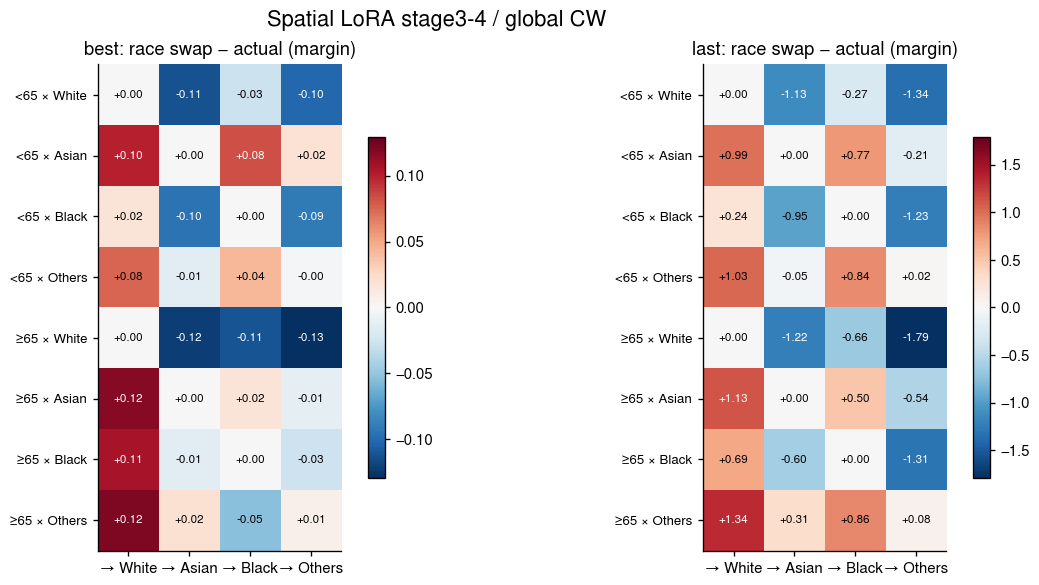

In [14]:
race_variants = list(RACE_CODES)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
for ax, kind in zip(axes, KINDS, strict=True):
    selected = cf_groups.query("condition == 'M06' and checkpoint == @kind and variant in @race_variants")
    matrix = selected.groupby(["group_id", "variant"]).mean_shift.mean().unstack()[race_variants]
    limit = np.abs(matrix.to_numpy()).max()
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit)
    for (row, col), value in np.ndenumerate(matrix.to_numpy()):
        color = "white" if abs(value) > 0.6 * limit else "black"
        ax.text(col, row, f"{value:+.2f}", ha="center", va="center", fontsize=7, color=color)
    ax.grid(False)
    ax.set_xticks(range(4), [f"→ {name}" for name in race_variants])
    ax.set_yticks(range(8), GROUP_LABELS, fontsize=8)
    ax.set_title(f"{kind}: race swap − actual (margin)")
    fig.colorbar(image, ax=ax, shrink=0.7)
fig.suptitle(SPATIAL["M06"])
fig.savefig(FIGURES / "counterfactual_race_shift_m06.png", dpi=160)
plt.show()

差し替えたvariantごとの8群AUROC（M06、3seed平均）。実際の属性（actual）と並べ、正しい属性を入れることが群内の識別に効いているかを見る。

In [15]:
actual_auroc = change_groups.query("condition == 'M06'").groupby(["checkpoint", "group_id"]).auroc_actual.mean()
variant_auroc = (
    cf_groups.query("condition == 'M06'").groupby(["checkpoint", "group_id", "variant"]).auroc.mean().unstack()
)
variant_auroc = variant_auroc[[*RACE_CODES, *COUNTERFACTUAL_AGES]].assign(actual=actual_auroc)
variant_auroc.index = variant_auroc.index.set_levels([KINDS, GROUP_LABELS], level=[0, 1])
variant_auroc.to_csv(RESULTS / "counterfactual_group_auroc_m06.csv")
display(variant_auroc.round(4))

variant                   White   Asian   Black  Others  age 50  age 75  \
checkpoint group_id                                                       
best       <65 × White   0.8823  0.8821  0.8815  0.8823  0.8824  0.8821   
           <65 × Asian   0.8695  0.8694  0.8693  0.8693  0.8697  0.8693   
           <65 × Black   0.8361  0.8350  0.8374  0.8354  0.8375  0.8381   
           <65 × Others  0.8512  0.8506  0.8502  0.8515  0.8512  0.8512   
           ≥65 × White   0.8127  0.8119  0.8137  0.8118  0.8126  0.8129   
           ≥65 × Asian   0.8279  0.8274  0.8298  0.8257  0.8232  0.8259   
           ≥65 × Black   0.8650  0.8654  0.8655  0.8683  0.8615  0.8654   
           ≥65 × Others  0.7324  0.7305  0.7341  0.7318  0.7337  0.7321   
last       <65 × White   0.8819  0.8777  0.8768  0.8754  0.8820  0.8803   
           <65 × Asian   0.8681  0.8660  0.8672  0.8614  0.8655  0.8618   
           <65 × Black   0.8375  0.8248  0.8364  0.8274  0.8370  0.8367   
           <65 × Others  0.8442  0.8402  0.8388  0.8377  0.8391  0.8333   
           ≥65 × White   0.8088  0.8009  0.8035  0.7974  0.8097  0.8091   
           ≥65 × Asian   0.8342  0.8287  0.8326  0.8258  0.8206  0.8267   
           ≥65 × Black   0.8558  0.8564  0.8598  0.8585  0.8586  0.8625   
           ≥65 × Others  0.7226  0.7259  0.7303  0.7216  0.7220  0.7195   

variant                  actual  
checkpoint group_id              
best       <65 × White   0.8823  
           <65 × Asian   0.8694  
           <65 × Black   0.8374  
           <65 × Others  0.8510  
           ≥65 × White   0.8127  
           ≥65 × Asian   0.8274  
           ≥65 × Black   0.8655  
           ≥65 × Others  0.7317  
last       <65 × White   0.8819  
           <65 × Asian   0.8660  
           <65 × Black   0.8364  
           <65 × Others  0.8377  
           ≥65 × White   0.8088  
           ≥65 × Asian   0.8287  
           ≥65 × Black   0.8598  
           ≥65 × Others  0.7171

## 4. metadata encoderのcondition空間

encoderが学習中に見たtrain集団の一意な属性組（3,467組、件数で重み付け）をconditionへ写す。

- 固有値比・participation ratio（(Σλ)²/Σλ²）：16次元のうち実質何次元を使っているか
- η²：各属性の値ごとの平均で説明できる分散の割合。属性どうしが相関するので足して1にはならない
- 感度：1属性だけ差し替えたときのcの移動量 / cの全体RMS広がり（categoricalは他の全値、年齢は+10歳）

encoderの出力空間での距離であり、ΔWや予測への効き方とは別。DROの群（年齢×race）以外の属性（sex・view）もencoderへ入る。

In [16]:
eigen_rows, share_rows, sensitivity_rows, spaces = [], [], [], {}
for (condition, seed), path in spatial_dirs.items():
    for kind in KINDS:
        table, values, shares, sensitivity = encoder_space(path, kind, DEVICE)
        keys = {"condition": condition, "seed": seed, "checkpoint": kind}
        spaces[condition, seed, kind] = table
        ratio = values / values.sum()
        eigen_rows.append(
            {
                **keys,
                **{f"pc{i + 1}": ratio[i] for i in range(4)},
                "participation_ratio": values.sum() ** 2 / (values**2).sum(),
            }
        )
        share_rows.append({**keys, **shares})
        sensitivity_rows.append({**keys, **sensitivity})
encoder_tables = {}
for name, rows in (("eigen", eigen_rows), ("variance_share", share_rows), ("swap_sensitivity", sensitivity_rows)):
    table = pd.DataFrame(rows)
    table.to_csv(RESULTS / f"encoder_{name}_by_seed.csv", index=False)
    encoder_tables[name] = (
        table.drop(columns="seed").groupby(["condition", "checkpoint"], sort=False).agg(["mean", "std"])
    )
    encoder_tables[name].to_csv(RESULTS / f"encoder_{name}_mean_std.csv")
    print(name)
    display(encoder_tables[name].xs("mean", axis=1, level=1).round(3))

eigen


pc1    pc2    pc3    pc4  participation_ratio
condition checkpoint                                                 
M06       best        0.295  0.231  0.164  0.118                5.224
          last        0.283  0.210  0.172  0.132                5.359
M13       best        0.427  0.199  0.148  0.085                3.900
          last        0.388  0.208  0.145  0.112                4.248
M19       best        0.298  0.246  0.141  0.111                5.225
          last        0.298  0.200  0.160  0.125                5.383
M20       best        0.475  0.186  0.129  0.072                3.506
          last        0.416  0.196  0.124  0.096                4.112

variance_share


sex   race  ethnicity  frontal_lateral  ap_pa  \
condition checkpoint                                                    
M06       best        0.175  0.240      0.124            0.152  0.301   
          last        0.159  0.364      0.172            0.099  0.200   
M13       best        0.111  0.277      0.126            0.077  0.153   
          last        0.166  0.271      0.138            0.071  0.147   
M19       best        0.170  0.267      0.149            0.136  0.254   
          last        0.144  0.376      0.182            0.082  0.189   
M20       best        0.112  0.219      0.094            0.073  0.143   
          last        0.156  0.247      0.131            0.066  0.139   

                      age decade  
condition checkpoint              
M06       best             0.184  
          last             0.185  
M13       best             0.388  
          last             0.359  
M19       best             0.193  
          last             0.184  
M20       best             0.448  
          last             0.394

swap_sensitivity


sex   race  ethnicity  frontal_lateral  ap_pa  \
condition checkpoint                                                    
M06       best        0.785  0.809      0.889            0.639  1.003   
          last        0.738  0.921      0.875            0.409  0.813   
M13       best        0.652  0.848      0.758            0.516  0.773   
          last        0.758  0.775      0.805            0.343  0.713   
M19       best        0.794  0.860      0.947            0.639  0.942   
          last        0.717  0.943      0.913            0.395  0.826   
M20       best        0.649  0.801      0.755            0.509  0.758   
          last        0.737  0.779      0.840            0.359  0.708   

                      age +10y  
condition checkpoint            
M06       best           0.225  
          last           0.222  
M13       best           0.308  
          last           0.289  
M19       best           0.231  
          last           0.223  
M20       best           0.333  
          last           0.308

M06 seed 42のPC1–PC2。点は一意な属性組、大きさは件数。属性ごとに色分けする（raceは4区分、viewはfrontal-AP / frontal-PA / lateral）。

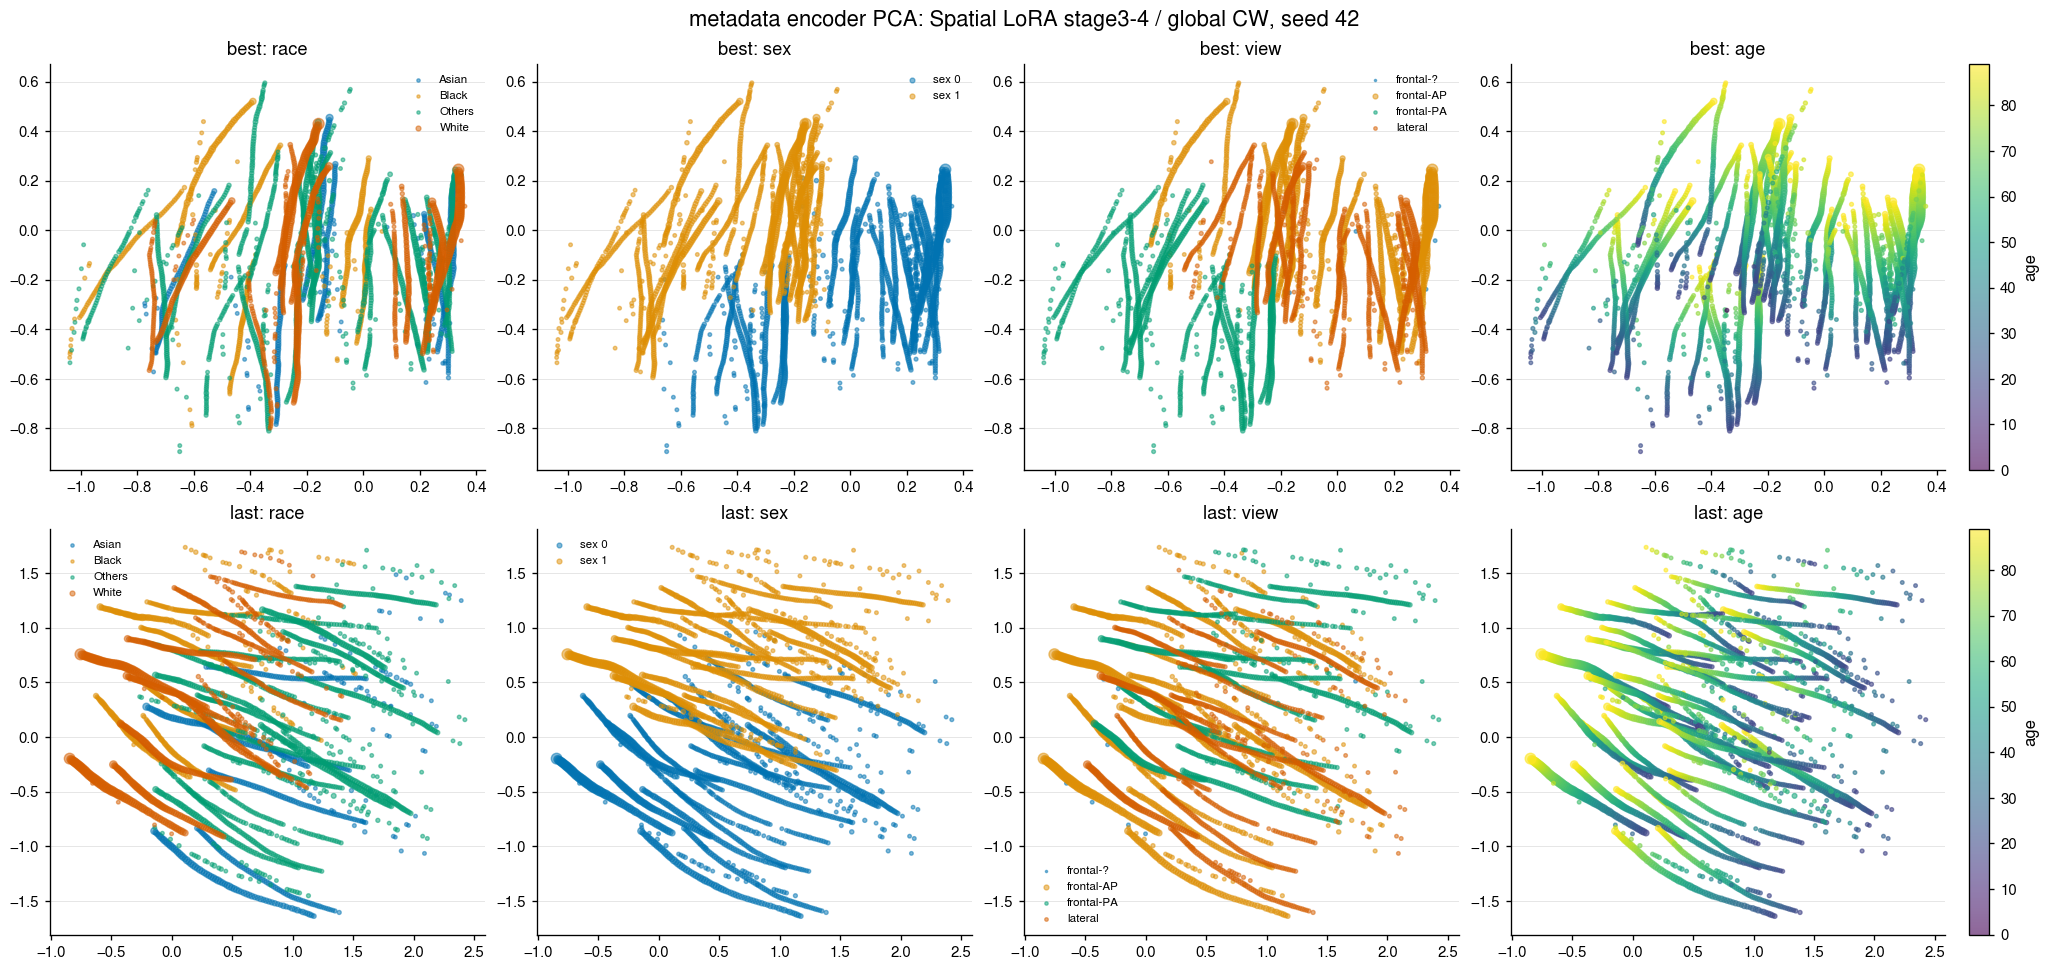

In [17]:
def view_label(table):
    lateral = table.frontal_lateral.to_numpy() == 1
    ap_pa = np.where(table.ap_pa_missing, "?", np.where(table.ap_pa == 0, "AP", "PA"))
    return np.where(lateral, "lateral", np.char.add("frontal-", ap_pa.astype(str)))


race_names = ["White", "Asian", "Black", "Others"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8), layout="constrained")
for row, kind in enumerate(KINDS):
    table = spaces["M06", 42, kind]
    size = 4 + 40 * np.sqrt(table["count"] / table["count"].max())
    categories = {
        "race": np.array(race_names)[table.race_group],
        "sex": np.where(table.sex == 0, "sex 0", "sex 1"),
        "view": view_label(table),
    }
    for col, (name, values) in enumerate(categories.items()):
        for value in sorted(set(values)):
            mask = values == value
            axes[row, col].scatter(table.pc1[mask], table.pc2[mask], s=size[mask], alpha=0.5, label=value)
        axes[row, col].legend(fontsize=7, markerscale=0.6)
        axes[row, col].set_title(f"{kind}: {name}")
    points = axes[row, 3].scatter(table.pc1, table.pc2, s=size, c=table.raw_age, cmap="viridis", alpha=0.6)
    fig.colorbar(points, ax=axes[row, 3], label="age")
    axes[row, 3].set_title(f"{kind}: age")
fig.suptitle(f"metadata encoder PCA: {SPATIAL['M06']}, seed 42")
fig.savefig(FIGURES / "encoder_pca_m06_s42.png", dpi=160)
plt.show()

8群（年齢×race）の重心間距離をseed間で比べる。encoderの座標はseedごとに任意の回転を持つので、距離行列の上三角どうしの
Spearman相関で幾何の再現性を見る。M06のbest/last。

In [18]:
def centroid_distances(table):
    columns = [name for name in table.columns if name.startswith("c") and name[1:].isdigit()]
    weights = table["count"].to_numpy(float)
    centroids = np.stack(
        [
            np.average(table.loc[table.group_id == g, columns], axis=0, weights=weights[table.group_id == g])
            for g in range(8)
        ]
    )
    distance = np.linalg.norm(centroids[:, None] - centroids[None], axis=-1)
    return distance[np.triu_indices(8, 1)]


rsa_rows = []
for condition in SPATIAL:
    for kind in KINDS:
        vectors = {seed: centroid_distances(spaces[condition, seed, kind]) for seed in SEEDS}
        for index, left in enumerate(SEEDS):
            for right in SEEDS[index + 1 :]:
                rho = pd.Series(vectors[left]).corr(pd.Series(vectors[right]), method="spearman")
                rsa_rows.append(
                    {"condition": condition, "checkpoint": kind, "seeds": f"{left}-{right}", "spearman": rho}
                )
rsa = pd.DataFrame(rsa_rows)
rsa.to_csv(RESULTS / "encoder_group_distance_rsa.csv", index=False)
display(rsa.pivot(index=["condition", "checkpoint"], columns="seeds", values="spearman").round(3))

seeds                 42-43  42-44  43-44
condition checkpoint                     
M06       best        0.799  0.525  0.454
          last        0.652  0.516  0.500
M13       best        0.799  0.467  0.356
          last        0.765  0.645  0.745
M19       best        0.723  0.569  0.363
          last        0.770  0.558  0.505
M20       best        0.889  0.689  0.839
          last        0.786  0.538  0.731

## まとめ・TODO

観察と解釈は`reports/two_stage_spatial_lora_inspection.md`に分けて記録する。
best checkpointのepochは早く、lastは補助診断であり性能比較には使わない。3seedで方式の優劣を断定しない。

TODO：

- epochごとのΔWの成長（best/last以外のcheckpointは保存されていない。必要なら追加学習で保存する）
- 1-stage Spatial LoRA（M03・M04）・HyperAdapt 2-stage（M10・M15）での同じ分解
- 反実仮想を他の属性（sex・view）へ広げ、encoderの感度と予測への効き方を対応づける
- Others（code 1・4・5）を別々に差し替えた場合の違い